# Multiclass Sentiment Analysis
## Neural Network, RNN, Bidirectional LSTM and Bidirectional GRU with Automated Hyperparameter Optimization

**Dataset:** `Sp1786/multiclass-sentiment-analysis-dataset`  
**Classes:** Negative, Neutral, Positive  
**Platform:** Google Colab (GPU strongly recommended)  
**Framework:** TensorFlow / Keras

This notebook investigates whether improved text representation, bidirectional sequence learning and systematic hyperparameter optimization improve multiclass sentiment classification. Four comparable architectures are implemented: a feedforward Neural Network, Simple RNN, Bidirectional LSTM and Bidirectional GRU.

## 1. Prerequisites Installation

In [1]:
!pip -q install pandas scikit-learn matplotlib seaborn

In [2]:
import os, re, json, time, random, gc, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import ParameterSampler

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the official dataset splits

In [3]:
BASE = "https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset/resolve/main"
train_df = pd.read_csv(f"{BASE}/train_df.csv")
val_df = pd.read_csv(f"{BASE}/val_df.csv")
test_df = pd.read_csv(f"{BASE}/test_df.csv")

print("Raw split sizes:", train_df.shape, val_df.shape, test_df.shape)
print("Columns:", train_df.columns.tolist())
display(train_df.head())

Raw split sizes: (31232, 4) (5205, 4) (5206, 4)
Columns: ['id', 'text', 'label', 'sentiment']


,id,text,label,sentiment
0,9536,"Cooking microwave pizzas, yummy",2,positive
1,6135,Any plans of allowing sub tasks to show up in ...,1,neutral
2,17697,"I love the humor, I just reworded it. Like sa...",2,positive
3,14182,naw idk what ur talkin about,1,neutral
4,17840,That sucks to hear. I hate days like that,0,negative


## 3. Clean data and verify labels

Rows with missing text or invalid labels are removed, so a split can end up slightly smaller than the raw file (the test split loses one row).

In [4]:
def clean_split(df):
    df = df[["text", "label"]].dropna().copy()
    df["text"] = df["text"].astype(str).str.strip()
    df["label"] = pd.to_numeric(df["label"], errors="coerce")
    df = df.dropna()
    df = df[df["text"].str.len() > 0]
    df["label"] = df["label"].astype(int)
    return df[df["label"].isin([0,1,2])].reset_index(drop=True)

train_df, val_df, test_df = map(clean_split, [train_df, val_df, test_df])
LABELS = ["Negative", "Neutral", "Positive"]
print("Clean split sizes:", len(train_df), len(val_df), len(test_df))
print("Label mapping: 0=Negative, 1=Neutral, 2=Positive")
display(train_df["label"].map(dict(enumerate(LABELS))).value_counts().to_frame("count"))

Clean split sizes: 31232 5205 5205
Label mapping: 0=Negative, 1=Neutral, 2=Positive


,count
label,
Neutral,11649
Positive,10478
Negative,9105


## 4. Exploratory analysis

,sentiment,count,percentage
0,Negative,9105,29.15
1,Neutral,11649,37.30
2,Positive,10478,33.55


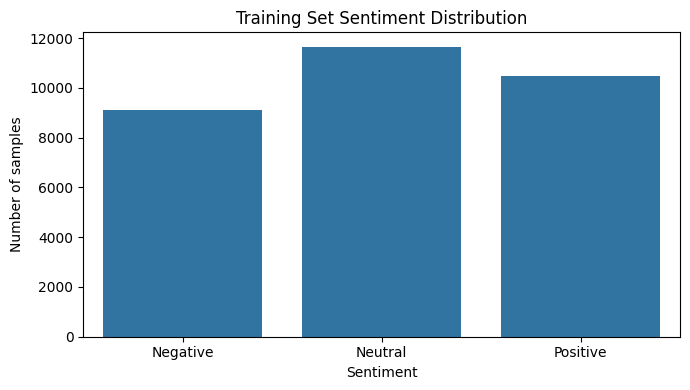

In [5]:
distribution = train_df["label"].value_counts().reindex([0,1,2], fill_value=0)
display(pd.DataFrame({
    "sentiment": LABELS,
    "count": distribution.values,
    "percentage": (distribution.values / distribution.sum() * 100).round(2)
}))
plt.figure(figsize=(7,4))
sns.barplot(x=LABELS, y=distribution.values)
plt.title("Training Set Sentiment Distribution")
plt.xlabel("Sentiment"); plt.ylabel("Number of samples")
plt.tight_layout(); plt.show()

## 5. Text normalization and tokenization
Avoid aggressive cleaning: punctuation, negation and expressive tokens can carry sentiment. This light normalization standardizes URLs and user mentions while preserving useful text.

In [6]:
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for frame in [train_df, val_df, test_df]:
    frame["clean_text"] = frame["text"].apply(normalize_text)

MAX_TOKENS = 30000
MAX_LEN = 120

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LEN,
    standardize=None
)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(
    train_df["clean_text"].values
).batch(1024))

X_train = vectorizer(train_df["clean_text"].values).numpy()
X_val = vectorizer(val_df["clean_text"].values).numpy()
X_test = vectorizer(test_df["clean_text"].values).numpy()
y_train, y_val, y_test = [f["label"].to_numpy() for f in [train_df,val_df,test_df]]
vocab = vectorizer.get_vocabulary()
VOCAB_SIZE = len(vocab)
print("Vocabulary size:", VOCAB_SIZE)
print("Tensor shapes:", X_train.shape, X_val.shape, X_test.shape)

Vocabulary size: 30000
Tensor shapes: (31232, 120) (5205, 120) (5205, 120)


## 6. Pretrained GloVe embeddings

All four models use pretrained 100-dimensional GloVe word vectors (`glove-wiki-gigaword-100`, downloaded through `gensim`) to initialize the embedding layer. This gives the models a semantic starting point, which helps because the dataset is not large enough to learn all word relationships from scratch. The embeddings remain trainable and are fine-tuned during training.

In [7]:
EMBEDDING_DIM = 100

!pip -q install gensim
import gensim.downloader as api

print("Loading pretrained GloVe vectors (first run downloads the model)...")
glove = api.load("glove-wiki-gigaword-100")

embedding_matrix = np.random.normal(
    0, 0.05, (VOCAB_SIZE, EMBEDDING_DIM)
).astype("float32")
embedding_matrix[0] = 0
hits = 0
for index, word in enumerate(vocab):
    if index == 0:
        continue
    if word in glove:
        embedding_matrix[index] = glove[word]
        hits += 1
print(f"GloVe coverage: {hits}/{VOCAB_SIZE} tokens ({hits/VOCAB_SIZE:.1%})")
del glove
gc.collect()

Loading pretrained GloVe vectors (first run downloads the model)...
[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe coverage: 12681/30000 tokens (42.3%)


2857

## 7. Address class imbalance

In [8]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(c): float(w) for c,w in zip(classes,weights)}
print("Class weights:", class_weights)

Class weights: {0: 1.1434010616877173, 1: 0.8936961684837039, 2: 0.9935738372462938}


## 8. Define four improved architectures

In [9]:
def build_model(architecture, embedding_dim=100, hidden_units=96,
                dropout=0.35, learning_rate=0.001):
    inputs = tf.keras.Input(shape=(MAX_LEN,), dtype="int32")
    assert embedding_dim == EMBEDDING_DIM, "Embedding size must match the GloVe vectors (100)"
    x = tf.keras.layers.Embedding(
        VOCAB_SIZE, embedding_dim,
        weights=[embedding_matrix], trainable=True, mask_zero=True
    )(inputs)

    if architecture == "NN":
        x = tf.keras.layers.GlobalAveragePooling1D()(x)
        x = tf.keras.layers.Dense(hidden_units, activation="relu")(x)
    elif architecture == "RNN":
        x = tf.keras.layers.SimpleRNN(hidden_units)(x)
    elif architecture == "LSTM":
        x = tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(hidden_units)
        )(x)
    elif architecture == "GRU":
        x = tf.keras.layers.Bidirectional(
            tf.keras.layers.GRU(hidden_units)
        )(x)
    else:
        raise ValueError("Unknown architecture")

    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(dropout/2)(x)
    outputs = tf.keras.layers.Dense(3, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name=architecture)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

build_model("LSTM").summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 120)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 120, 100)  │  3,000,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 120)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 192)       │    151,296 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 192)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     12,352 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,163,843 (12.07 MB)

 Trainable params: 3,163,843 (12.07 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Hyperparameter search space

In [10]:
PARAM_GRID = {
    "embedding_dim": [100],  # fixed to the GloVe vector size
    "hidden_units": [64, 96, 128],
    "dropout": [0.25, 0.35, 0.5],
    "learning_rate": [0.001, 0.0005, 0.0002],
    "batch_size": [64, 128]
}
TRIALS_PER_MODEL = 12
TUNING_EPOCHS = 6
FINAL_EPOCHS = 15
PATIENCE = 3

print("Possible combinations per architecture:",
      int(np.prod([len(v) for v in PARAM_GRID.values()])))
print("Trials per architecture:", TRIALS_PER_MODEL)
print("Total tuning trials:", 4 * TRIALS_PER_MODEL)

Possible combinations per architecture: 54
Trials per architecture: 12
Total tuning trials: 48


## 10. Automated hyperparameter tuning (random search with early stopping)

In [11]:
trial_rows = []
best_configs = {}

for arch in ["NN", "RNN", "LSTM", "GRU"]:
    print("\n", "="*50, "\nTUNING", arch, "\n", "="*50)
    sampler = list(ParameterSampler(
        PARAM_GRID, n_iter=TRIALS_PER_MODEL, random_state=SEED
    ))
    for trial, params in enumerate(sampler, 1):
        tf.keras.backend.clear_session(); gc.collect()

        # Separate batch_size from the other parameters passed to build_model
        model_params = {k: v for k, v in params.items() if k != "batch_size"}
        model = build_model(arch, **model_params)

        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=PATIENCE, restore_best_weights=True
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5
            )
        ]
        start = time.time()
        hist = model.fit(
            X_train, y_train, validation_data=(X_val,y_val),
            epochs=TUNING_EPOCHS, batch_size=params["batch_size"],
            class_weight=class_weights, callbacks=callbacks, verbose=0
        )
        duration = time.time()-start
        val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
        val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        val_acc = accuracy_score(y_val, val_pred)
        row = {
            "architecture":arch, "trial":trial, **params,
            "val_accuracy":val_acc, "val_macro_f1":val_f1,
            "best_val_loss":float(min(hist.history["val_loss"])),
            "epochs_run":len(hist.history["loss"]), "seconds":duration
        }
        trial_rows.append(row)
        print(f"{arch} trial {trial:02d}: val_accuracy={val_acc:.4f}, "
              f"val_macro_F1={val_f1:.4f}")
        del model; gc.collect()

    candidates = [r for r in trial_rows if r["architecture"]==arch]
    best_configs[arch] = max(candidates,key=lambda r:r["val_macro_f1"])
    print("Selected validation macro-F1:",round(best_configs[arch]["val_macro_f1"],4))
    print("Selected parameters:",{k:best_configs[arch][k] for k in PARAM_GRID})


TUNING NN 
NN trial 01: val_accuracy=0.6515, val_macro_F1=0.6550
NN trial 02: val_accuracy=0.6569, val_macro_F1=0.6579
NN trial 03: val_accuracy=0.6534, val_macro_F1=0.6560
NN trial 04: val_accuracy=0.6515, val_macro_F1=0.6555
NN trial 05: val_accuracy=0.6334, val_macro_F1=0.6347
NN trial 06: val_accuracy=0.6548, val_macro_F1=0.6560
NN trial 07: val_accuracy=0.6398, val_macro_F1=0.6422
NN trial 08: val_accuracy=0.6500, val_macro_F1=0.6517
NN trial 09: val_accuracy=0.6523, val_macro_F1=0.6569
NN trial 10: val_accuracy=0.6296, val_macro_F1=0.6305
NN trial 11: val_accuracy=0.6490, val_macro_F1=0.6521
NN trial 12: val_accuracy=0.6476, val_macro_F1=0.6509
Selected validation macro-F1: 0.6579
Selected parameters: {'embedding_dim': 100, 'hidden_units': 96, 'dropout': 0.5, 'learning_rate': 0.0005, 'batch_size': 128}

TUNING RNN 
RNN trial 01: val_accuracy=0.6373, val_macro_F1=0.6413
RNN trial 02: val_accuracy=0.6461, val_macro_F1=0.6485
RNN trial 03: val_accuracy=0.6302, val_macro_F1=0.6324
R

## 11. Validation comparison

,architecture,val_accuracy,val_macro_f1,embedding_dim,hidden_units,dropout,learning_rate,batch_size
1,LSTM,0.676465,0.680999,100,96,0.25,0.0010,64
0,GRU,0.675889,0.680628,100,96,0.25,0.0010,64
2,NN,0.656868,0.657857,100,96,0.50,0.0005,128
3,RNN,0.647070,0.650420,100,96,0.35,0.0005,64


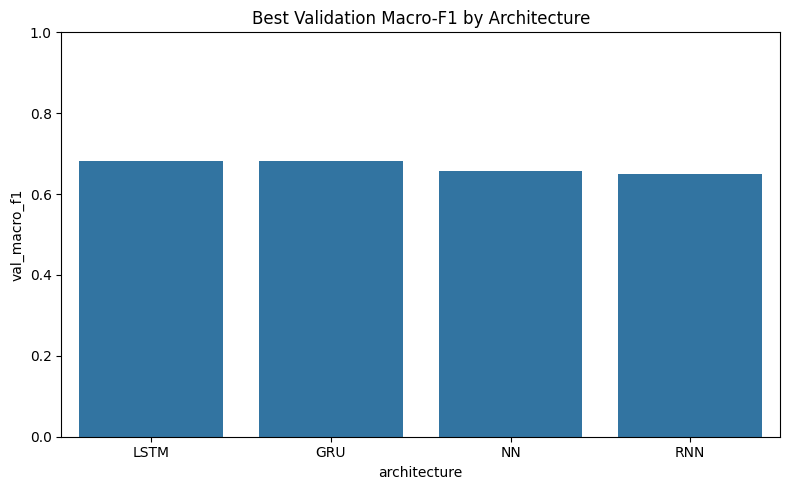

In [12]:
tuning_df = pd.DataFrame(trial_rows)
best_val_df = (tuning_df.sort_values("val_macro_f1",ascending=False)
               .groupby("architecture",as_index=False).first()
               .sort_values("val_macro_f1",ascending=False))
display(best_val_df[["architecture","val_accuracy","val_macro_f1",
                     "embedding_dim","hidden_units","dropout",
                     "learning_rate","batch_size"]])
plt.figure(figsize=(8,5))
sns.barplot(data=best_val_df,x="architecture",y="val_macro_f1")
plt.title("Best Validation Macro-F1 by Architecture")
plt.ylim(0,1); plt.tight_layout(); plt.show()

## 12. Retrain the selected configuration for each architecture

In [13]:
final_models, histories, test_preds, test_rows = {}, {}, {}, []
for arch in ["NN","RNN","LSTM","GRU"]:
    params = {k:best_configs[arch][k] for k in PARAM_GRID}
    tf.keras.backend.clear_session(); gc.collect()
    # Separate batch_size from the other parameters passed to build_model
    model_params = {k: v for k, v in params.items() if k != "batch_size"}
    model = build_model(arch, **model_params)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",patience=4,restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",factor=0.5,patience=2,min_lr=1e-5
        )
    ]
    start=time.time()
    history=model.fit(
        X_train,y_train,validation_data=(X_val,y_val),
        epochs=FINAL_EPOCHS,batch_size=params["batch_size"],
        class_weight=class_weights,callbacks=callbacks,verbose=1
    )
    duration=time.time()-start
    pred=model.predict(X_test,verbose=0).argmax(axis=1)
    precision,recall,macro_f1,_=precision_recall_fscore_support(
        y_test,pred,average="macro",zero_division=0
    )
    final_models[arch]=model; histories[arch]=history; test_preds[arch]=pred
    test_rows.append({
        "architecture":arch,"test_accuracy":accuracy_score(y_test,pred),
        "macro_precision":precision,"macro_recall":recall,
        "test_macro_f1":macro_f1,"training_seconds":duration,**params
    })

Epoch 1/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4310 - loss: 1.0507 - val_accuracy: 0.5560 - val_loss: 0.9353 - learning_rate: 5.0000e-04
Epoch 2/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5605 - loss: 0.9011 - val_accuracy: 0.6025 - val_loss: 0.8434 - learning_rate: 5.0000e-04
Epoch 3/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6241 - loss: 0.8106 - val_accuracy: 0.6298 - val_loss: 0.8036 - learning_rate: 5.0000e-04
Epoch 4/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6668 - loss: 0.7429 - val_accuracy: 0.6475 - val_loss: 0.7844 - learning_rate: 5.0000e-04
Epoch 5/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7003 - loss: 0.6929 - val_accuracy: 0.6532 - val_loss: 0.7779 - learning_rate: 5.0000e-04
Epoch 6/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7285 - loss: 0.6413 - val_accuracy: 0.6538 - val_loss: 0.7873 - learning_rate: 5.0000e-04
Epoch 7/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy:

## 13. Final test comparison and best model

In [14]:
comparison = pd.DataFrame(test_rows).sort_values(
    ["test_macro_f1","test_accuracy"],ascending=False
).reset_index(drop=True)
display(comparison)
winner=comparison.iloc[0]
best_arch=winner["architecture"]
print("BEST OBSERVED MODEL:",best_arch)
print("Test accuracy:",round(winner["test_accuracy"],4))
print("Macro precision:",round(winner["macro_precision"],4))
print("Macro recall:",round(winner["macro_recall"],4))
print("Test macro-F1:",round(winner["test_macro_f1"],4))
print("Selected hyperparameters:")
for p in PARAM_GRID: print(p,":",winner[p])

,architecture,test_accuracy,macro_precision,macro_recall,test_macro_f1,training_seconds,embedding_dim,hidden_units,dropout,learning_rate,batch_size
0,GRU,0.689721,0.697234,0.692490,0.693652,48.797075,100,96,0.25,0.0010,64
1,LSTM,0.686647,0.692772,0.689486,0.690332,50.012717,100,96,0.25,0.0010,64
2,NN,0.649376,0.647181,0.656552,0.649471,17.470827,100,96,0.50,0.0005,128
3,RNN,0.640154,0.646476,0.639801,0.642329,50.350412,100,96,0.35,0.0005,64


BEST OBSERVED MODEL: GRU
Test accuracy: 0.6897
Macro precision: 0.6972
Macro recall: 0.6925
Test macro-F1: 0.6937
Selected hyperparameters:
embedding_dim : 100
hidden_units : 96
dropout : 0.25
learning_rate : 0.001
batch_size : 64


## 14. Classification report and confusion matrix

              precision    recall  f1-score   support

    Negative     0.6790    0.7238    0.7007      1546
     Neutral     0.6201    0.6490    0.6342      1929
    Positive     0.7926    0.7046    0.7460      1730

    accuracy                         0.6897      5205
   macro avg     0.6972    0.6925    0.6937      5205
weighted avg     0.6949    0.6897    0.6911      5205



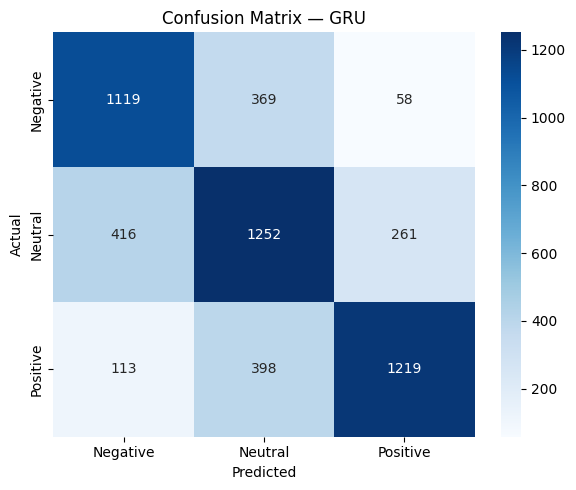

In [15]:
print(classification_report(
    y_test,test_preds[best_arch],labels=[0,1,2],
    target_names=LABELS,digits=4,zero_division=0
))
cm=confusion_matrix(y_test,test_preds[best_arch],labels=[0,1,2])
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
            xticklabels=LABELS,yticklabels=LABELS)
plt.title(f"Confusion Matrix — {best_arch}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

## 15. Learning curves

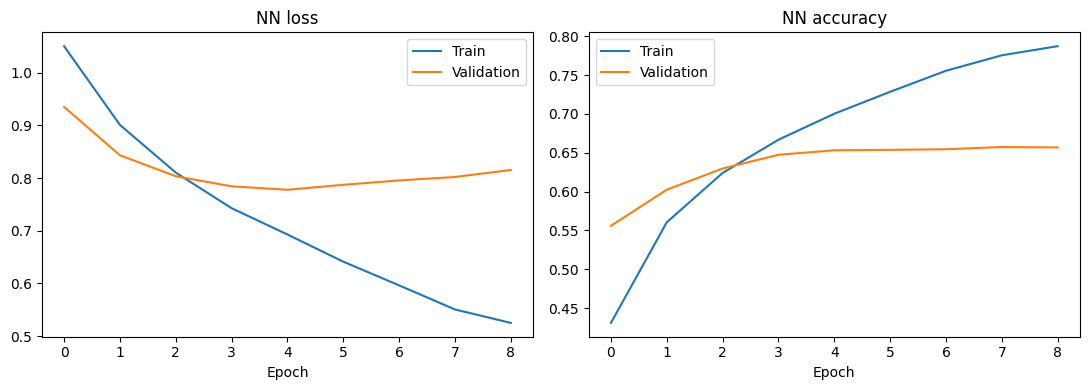

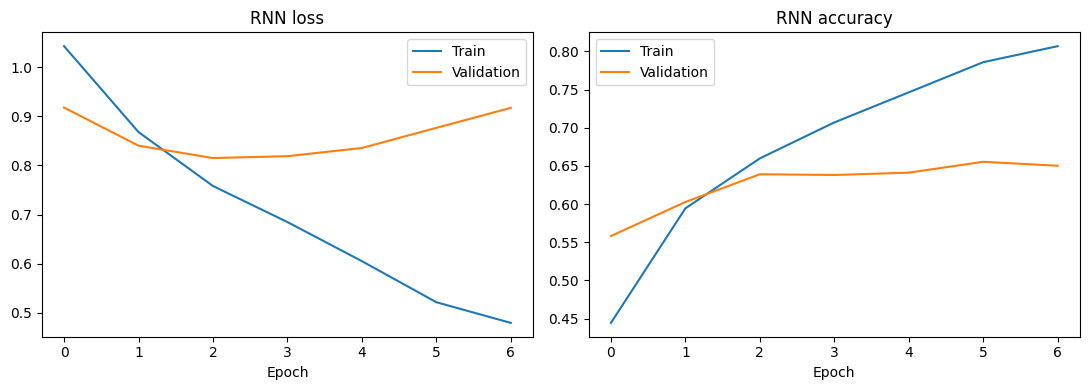

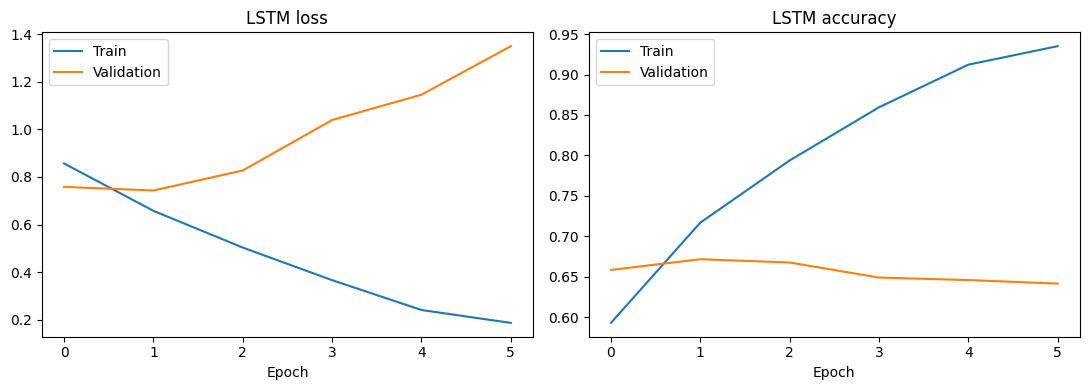

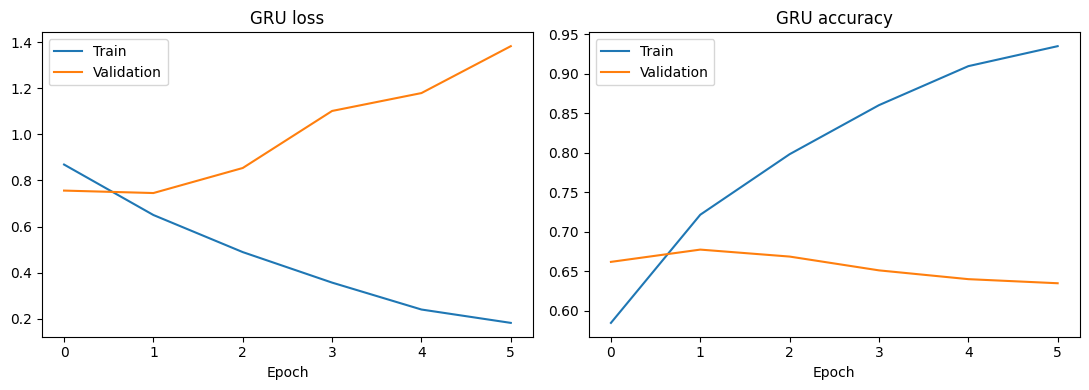

In [16]:
for arch,h in histories.items():
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    ax[0].plot(h.history["loss"],label="Train")
    ax[0].plot(h.history["val_loss"],label="Validation")
    ax[0].set_title(arch+" loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(h.history["accuracy"],label="Train")
    ax[1].plot(h.history["val_accuracy"],label="Validation")
    ax[1].set_title(arch+" accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 16. Inference on new sentences

In [17]:
def predict_sentiment(texts):
    normalized=[normalize_text(t) for t in texts]
    sequences=vectorizer(np.array(normalized)).numpy()
    probabilities=final_models[best_arch].predict(sequences,verbose=0)
    ids=probabilities.argmax(axis=1)
    return pd.DataFrame({
        "text":texts,
        "predicted_sentiment":[LABELS[int(i)] for i in ids],
        "confidence":probabilities.max(axis=1).round(4)
    })

display(predict_sentiment([
    "I absolutely love this product. It is wonderful!",
    "The experience was average",
    "This is terrible and I am very disappointed.",
    "I ate an ice cream and it was so yummy"
]))

,text,predicted_sentiment,confidence
0,I absolutely love this product. It is wonderful!,Positive,0.9252
1,The experience was average,Neutral,0.5435
2,This is terrible and I am very disappointed.,Negative,0.9970
3,I ate an ice cream and it was so yummy,Positive,0.9100


## 17. Save models and experiment artefacts

In [18]:
OUT="sentiment_high_performance_results"
os.makedirs(OUT,exist_ok=True)
for arch,model in final_models.items():
    model.save(os.path.join(OUT,f"{arch.lower()}_model.keras"))
tuning_df.to_csv(os.path.join(OUT,"hyperparameter_trials.csv"),index=False)
best_val_df.to_csv(os.path.join(OUT,"best_validation_models.csv"),index=False)
comparison.to_csv(os.path.join(OUT,"test_comparison.csv"),index=False)
summary={
    "best_observed_model":str(best_arch),
    "test_accuracy":float(winner["test_accuracy"]),
    "test_macro_f1":float(winner["test_macro_f1"]),
    "pretrained_glove_used":True,
    "hyperparameters":{k:(int(winner[k]) if k in ["embedding_dim","hidden_units","batch_size"] else float(winner[k])) for k in PARAM_GRID}
}
with open(os.path.join(OUT,"summary.json"),"w") as f: json.dump(summary,f,indent=2)
import shutil
zip_path=shutil.make_archive(OUT,"zip",OUT)
print("Saved result archive:",zip_path)
# In Colab, uncomment to download:
# from google.colab import files
# files.download(zip_path)

Saved result archive: /content/sentiment_high_performance_results.zip


## 18. Conclusion

1. Loaded the multiclass sentiment dataset (Negative, Neutral, Positive) from Hugging Face with predefined train, validation and test splits.
2. Cleaned the data, normalized URLs and user mentions, and tokenized the text.
3. Initialized the embedding layer with pretrained GloVe vectors and handled class imbalance with class weights.
4. Implemented four models: Neural Network (NN), Simple RNN, Bidirectional LSTM and Bidirectional GRU.
5. Tuned hidden units, dropout, learning rate and batch size automatically using random search over a predefined grid (12 trials per model), with early stopping and learning-rate reduction.
6. Selected each model's best configuration by validation macro-F1, retrained it, and evaluated it once on the test set using accuracy, precision, recall and macro-F1.
7. Identified the best-performing model and its hyperparameters (printed by the cell below).
8. Results come from a single run with one random seed, so models with very close scores should be treated as comparable rather than definitively ranked.

In [19]:
if 'best_arch' not in globals() or 'winner' not in globals() or 'comparison' not in globals():
    print("Error: Training variables not found in memory.")
    print("Please run all previous cells (or go to Runtime -> Run all) to start the experiment and populate the results!")
else:
    print("FINAL RESULT")
    print("Best model:", best_arch)
    print(f"Test accuracy: {winner['test_accuracy']:.4f} | Test macro-F1: {winner['test_macro_f1']:.4f}")
    print("Best hyperparameters:", {p: winner[p] for p in PARAM_GRID if p in winner})
    print("\nRanking by test macro-F1:")
    for rank, row in comparison.iterrows():
        print(f"  {rank+1}. {row['architecture']:<5} accuracy={row['test_accuracy']:.4f}  macro-F1={row['test_macro_f1']:.4f}")

FINAL RESULT
Best model: GRU
Test accuracy: 0.6897 | Test macro-F1: 0.6937
Best hyperparameters: {'embedding_dim': np.int64(100), 'hidden_units': np.int64(96), 'dropout': np.float64(0.25), 'learning_rate': np.float64(0.001), 'batch_size': np.int64(64)}

Ranking by test macro-F1:
  1. GRU   accuracy=0.6897  macro-F1=0.6937
  2. LSTM  accuracy=0.6866  macro-F1=0.6903
  3. NN    accuracy=0.6494  macro-F1=0.6495
  4. RNN   accuracy=0.6402  macro-F1=0.6423
